In [15]:
import numpy as np
import pandas as pd

# Load the dataset and chek the info and description of the data

df = pd.read_csv("Healthcare.csv", sep=",")
df.drop("Patient_ID", axis=1, inplace=True)
df.info()
df.describe(include="all")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Age            25000 non-null  int64 
 1   Gender         25000 non-null  object
 2   Symptoms       25000 non-null  object
 3   Symptom_Count  25000 non-null  int64 
 4   Disease        25000 non-null  object
dtypes: int64(2), object(3)
memory usage: 976.7+ KB


,Age,Gender,Symptoms,Symptom_Count,Disease
count,25000.000000,25000,25000,25000.000000,25000
unique,NaN,3,24359,NaN,30
top,NaN,Other,"sweating, abdominal pain, shortness of breath",NaN,Anxiety
freq,NaN,8393,4,NaN,911
mean,45.302240,NaN,NaN,5.001440,NaN
std,26.106224,NaN,NaN,1.415796,NaN
min,1.000000,NaN,NaN,3.000000,NaN
25%,23.000000,NaN,NaN,4.000000,NaN
50%,45.000000,NaN,NaN,5.000000,NaN
75%,68.000000,NaN,NaN,6.000000,NaN


In [16]:
print(df.head())

   Age  Gender                                           Symptoms  \
0   29    Male              fever, back pain, shortness of breath   
1   76  Female                   insomnia, back pain, weight loss   
2   78    Male                    sore throat, vomiting, diarrhea   
3   58   Other  blurred vision, depression, weight loss, muscl...   
4   55  Female                    swelling, appetite loss, nausea   

   Symptom_Count           Disease  
0              3           Allergy  
1              3  Thyroid Disorder  
2              3         Influenza  
3              4            Stroke  
4              3     Heart Disease  


In [17]:
df["Gender"] = df["Gender"].astype(str).str.strip()
df["Disease"] = df["Disease"].astype(str).str.strip()

In [18]:
# One Hot encoding pour la variable Symptomes

df["Symptoms"] = df["Symptoms"].astype(str).str.lower()

def split_symptoms(s):
    parts = [x.strip() for x in s.split(",")]
    return [p for p in parts if p != ""]

df["Symptoms_list"] = df["Symptoms"].apply(split_symptoms)

exploded = df[["Symptoms_list"]].explode("Symptoms_list")
symptom_ohe = pd.crosstab(exploded.index, exploded["Symptoms_list"])
symptom_ohe = symptom_ohe.reindex(df.index, fill_value=0)


In [19]:
from sklearn.preprocessing import LabelEncoder


#Creation de notre dataset final avec le one hot encoding sur les varibales categorieles Symptomes et Gender
 
gender_ohe = pd.get_dummies(df["Gender"], prefix="Gender")
num = df[["Age", "Symptom_Count"]].copy()

X = pd.concat([num, gender_ohe, symptom_ohe], axis=1)
y = df["Disease"]

# Label encoding pour la variable cible Disease

le = LabelEncoder()
y = le.fit_transform(df["Disease"])

num_classes = len(le.classes_)
print("num_classes =", num_classes)

X = X.astype(np.float32)


df = X.copy()
df["Disease"] = y
df.to_csv("Healthcare_rebuilt.csv", index=False)


num_classes = 30


In [20]:
df.isna().sum()

Age                    0
Symptom_Count          0
Gender_Female          0
Gender_Male            0
Gender_Other           0
abdominal pain         0
anxiety                0
appetite loss          0
back pain              0
blurred vision         0
chest pain             0
cough                  0
depression             0
diarrhea               0
dizziness              0
fatigue                0
fever                  0
headache               0
insomnia               0
joint pain             0
muscle pain            0
nausea                 0
rash                   0
runny nose             0
shortness of breath    0
sneezing               0
sore throat            0
sweating               0
swelling               0
tremors                0
vomiting               0
weight gain            0
weight loss            0
Disease                0
dtype: int64

In [ ]:
from sklearn.model_selection import train_test_split

# Split the data into training, validation, and test sets (60% train, 20% val, 20% test)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)


print(len(y_train), len(y_val), len(y_test))
print(np.bincount(y_train).min(), np.bincount(y_train).max())


20000 2500 2500
626 729


In [22]:
# Normalisation des données numériques Age et Symptom_Count

from sklearn.preprocessing import StandardScaler

num_cols = ["Age", "Symptom_Count"]
scaler = StandardScaler()

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_val[num_cols]   = scaler.transform(X_val[num_cols])
X_test[num_cols]  = scaler.transform(X_test[num_cols])
print(X_train.head())

            Age  Symptom_Count  Gender_Female  Gender_Male  Gender_Other  \
6243  -0.547010      -1.414868            0.0          1.0           0.0   
3338  -1.390821      -1.414868            1.0          0.0           0.0   
21525 -1.505887       0.706214            1.0          0.0           0.0   
24545 -0.585365      -0.000813            1.0          0.0           0.0   
12398 -0.125105      -0.000813            0.0          0.0           1.0   

       abdominal pain  anxiety  appetite loss  back pain  blurred vision  ...  \
6243              0.0      0.0            1.0        1.0             0.0  ...   
3338              0.0      0.0            0.0        0.0             0.0  ...   
21525             0.0      0.0            0.0        1.0             0.0  ...   
24545             0.0      0.0            1.0        0.0             0.0  ...   
12398             0.0      0.0            1.0        0.0             1.0  ...   

       runny nose  shortness of breath  sneezing  sore t

In [ ]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Convertir les données en tenseurs PyTorch et créer les DataLoaders


X_train_t = torch.tensor(X_train.values, dtype=torch.float32)
X_val_t   = torch.tensor(X_val.values, dtype=torch.float32)
X_test_t  = torch.tensor(X_test.values, dtype=torch.float32)

y_train_t = torch.tensor(y_train, dtype=torch.long)
y_val_t   = torch.tensor(y_val, dtype=torch.long)
y_test_t  = torch.tensor(y_test, dtype=torch.long)

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=64, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=256, shuffle=False)
test_loader  = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=256, shuffle=False)

In [27]:
print(X_train_t.shape, y_train_t.shape)
print(X_train_t.dtype, y_train_t.dtype)

torch.Size([20000, 33]) torch.Size([20000])
torch.float32 torch.int64


In [60]:
import torch 
import torch.nn as nn

# Define the MLP model for multiclass classification

class MLP_multiclass(nn.Module):
    def __init__(self, input_dim, num_classes, dropout=0.1):
        super(MLP_multiclass, self).__init__()
        self.fc1 = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(dropout))
        self.fc2 = nn.Sequential(
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(dropout))
        self.fc3 = nn.Sequential(
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(dropout))
        self.fc4 = nn.Linear(64, num_classes)

    def forward(self, x):
        x = self.fc1(x)
        x = self.fc2(x)
        x = self.fc3(x)
        x = self.fc4(x) 
        return x
    

model = MLP_multiclass(input_dim=X_train.shape[1], num_classes=num_classes, dropout=0.1)
print(model)

MLP_multiclass(
  (fc1): Sequential(
    (0): Linear(in_features=33, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.1, inplace=False)
  )
  (fc2): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.1, inplace=False)
  )
  (fc3): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.1, inplace=False)
  )
  (fc4): Linear(in_features=64, out_features=30, bias=True)
)


In [61]:
# Define the device, loss function and optimizer

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

In [62]:
# Fonction pour entrainer et évaluer le modèle


def run_epoch_cls(loader, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0.0, 0, 0

    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)

        if train:
            optimizer.zero_grad()

        with torch.set_grad_enabled(train):
            logits = model(xb)
            loss = criterion(logits, yb)

            if train:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * xb.size(0)
        preds = torch.argmax(logits, dim=1)
        correct += (preds == yb).sum().item()
        total += xb.size(0)

    return total_loss / total, correct / total

In [63]:
# Training loop with early stopping based on validation loss

best_val = float("inf")
patience, wait = 15, 0
best_state = None

train_hist, val_hist = [], []

for epoch in range(1, 501):
    train_loss, train_acc = run_epoch_cls(train_loader, train=True)
    val_loss, val_acc     = run_epoch_cls(val_loader, train=False)

    train_hist.append((train_loss, train_acc))
    val_hist.append((val_loss, val_acc))

    if val_loss < best_val - 1e-6:
        best_val = val_loss
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        wait = 0
    else:
        wait += 1
        if wait >= patience:
            break

model.load_state_dict(best_state)

<All keys matched successfully>

In [65]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

model.eval()
preds, trues = [], []

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)
        logits = model(xb).cpu()
        pred = torch.argmax(logits, dim=1).numpy()
        preds.append(pred)
        trues.append(yb.numpy())

y_pred = np.concatenate(preds)
y_true = np.concatenate(trues)

acc = accuracy_score(y_true, y_pred)
f1m = f1_score(y_true, y_pred, average="macro")

print("Test Accuracy:", acc)
print("Test F1-macro:", f1m)
print(classification_report(y_true, y_pred, target_names=le.classes_))

Test Accuracy: 0.032
Test F1-macro: 0.02812011327434487
                        precision    recall  f1-score   support

               Allergy       0.03      0.03      0.03        86
                Anemia       0.04      0.05      0.05        82
               Anxiety       0.04      0.07      0.05        91
             Arthritis       0.05      0.08      0.06        89
                Asthma       0.07      0.04      0.05        78
            Bronchitis       0.02      0.02      0.02        85
              COVID-19       0.05      0.10      0.07        84
Chronic Kidney Disease       0.00      0.00      0.00        80
           Common Cold       0.00      0.00      0.00        81
              Dementia       0.00      0.00      0.00        83
            Depression       0.03      0.07      0.04        86
            Dermatitis       0.00      0.00      0.00        85
              Diabetes       0.03      0.01      0.02        85
              Epilepsy       0.00      0.00    

In [33]:
print(y_train_t.shape)
print(y_train_t.dtype)
print(y_train_t.min(), y_train_t.max())

torch.Size([20000])
torch.int64
tensor(0) tensor(29)


In [49]:
import torch
import matplotlib.pyplot as plt
import numpy as np

def lr_finder(model, loader, optimizer, criterion, device,
              start_lr=1e-6, end_lr=1, num_iter=100):

    model.train()
    
    lrs = []
    losses = []

    lr = start_lr
    mult = (end_lr / start_lr) ** (1 / num_iter)

    for param_group in optimizer.param_groups:
        param_group["lr"] = lr

    iterator = iter(loader)

    for iteration in range(num_iter):

        try:
            xb, yb = next(iterator)
        except StopIteration:
            iterator = iter(loader)
            xb, yb = next(iterator)

        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        outputs = model(xb)
        loss = criterion(outputs, yb)
        loss.backward()
        optimizer.step()

        lrs.append(lr)
        losses.append(loss.item())

        lr *= mult
        for param_group in optimizer.param_groups:
            param_group["lr"] = lr

        if loss.item() > 10:  # early stop si explosion
            break

    return lrs, losses

In [50]:
model = MLP_multiclass(input_dim=X_train_t.shape[1], num_classes=num_classes).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-6)

lrs, losses = lr_finder(model, train_loader, optimizer, criterion, device)

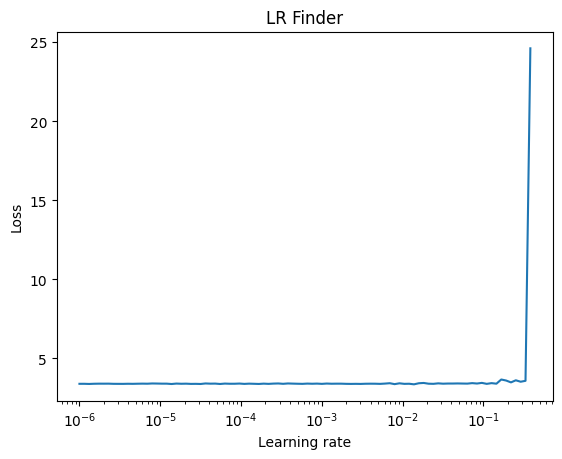

In [51]:
plt.plot(lrs, losses)
plt.xscale("log")
plt.xlabel("Learning rate")
plt.ylabel("Loss")
plt.title("LR Finder")
plt.show()

In [39]:
with torch.no_grad():
    xb, _ = next(iter(train_loader))
    out = model(xb.to(device))
    print(out[0])

tensor([ 0.7584, -0.6431,  0.6315,  0.2864, -0.0543, -0.2044,  0.1845,  0.0079,
         0.0368, -0.5332,  0.0446, -0.0720,  0.6008, -0.6048, -0.1317, -0.8690,
        -0.0192,  0.2297, -0.3764,  0.3683,  0.2065, -0.2989, -0.2041, -0.2579,
        -0.2398,  0.6346,  0.4031,  0.4420, -0.1591, -0.5484])


In [40]:
print(X_train_t.shape)
print(torch.std(X_train_t, dim=0))

torch.Size([20000, 33])
tensor([1.0000, 1.0000, 0.4709, 0.4708, 0.4726, 0.3792, 0.3839, 0.3866, 0.3831,
        0.3844, 0.3805, 0.3829, 0.3833, 0.3819, 0.3809, 0.3822, 0.3854, 0.3863,
        0.3799, 0.3814, 0.3858, 0.3835, 0.3806, 0.3821, 0.3810, 0.3886, 0.3834,
        0.3827, 0.3846, 0.3817, 0.3839, 0.3824, 0.3823])


In [41]:
print(X_train.head())
print(y_train[:5])

            Age  Symptom_Count  Gender_Female  Gender_Male  Gender_Other  \
6243  -0.547010      -1.414868            0.0          1.0           0.0   
3338  -1.390821      -1.414868            1.0          0.0           0.0   
21525 -1.505887       0.706214            1.0          0.0           0.0   
24545 -0.585365      -0.000813            1.0          0.0           0.0   
12398 -0.125105      -0.000813            0.0          0.0           1.0   

       abdominal pain  anxiety  appetite loss  back pain  blurred vision  ...  \
6243              0.0      0.0            1.0        1.0             0.0  ...   
3338              0.0      0.0            0.0        0.0             0.0  ...   
21525             0.0      0.0            0.0        1.0             0.0  ...   
24545             0.0      0.0            1.0        0.0             0.0  ...   
12398             0.0      0.0            1.0        0.0             1.0  ...   

       runny nose  shortness of breath  sneezing  sore t

In [42]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

clf = LogisticRegression(max_iter=2000, n_jobs=-1)
clf.fit(X_train, y_train)
pred = clf.predict(X_test)

print("Acc:", accuracy_score(y_test, pred))
print("F1 macro:", f1_score(y_test, pred, average="macro"))

c:\Users\falaq\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Acc: 0.0396
F1 macro: 0.03681171585134736


In [66]:
import torch
import numpy as np

# Prendre un petit sous-ensemble
idx = torch.randperm(len(X_train_t))[:500]
X_small = X_train_t[idx].to(device)
y_small = y_train_t[idx].to(device)

model = MLP_multiclass(input_dim=X_train_t.shape[1], num_classes=num_classes, dropout=0.1).to(device)
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(1, 201):
    model.train()
    optimizer.zero_grad()
    logits = model(X_small)
    loss = criterion(logits, y_small)
    loss.backward()
    optimizer.step()

    if epoch % 20 == 0:
        pred = logits.argmax(dim=1)
        acc = (pred == y_small).float().mean().item()
        print(f"epoch {epoch} | loss {loss.item():.3f} | acc {acc:.3f}")

epoch 20 | loss 2.714 | acc 0.418
epoch 40 | loss 2.189 | acc 0.624
epoch 60 | loss 1.643 | acc 0.790
epoch 80 | loss 1.089 | acc 0.934
epoch 100 | loss 0.728 | acc 0.972
epoch 120 | loss 0.450 | acc 0.988
epoch 140 | loss 0.303 | acc 0.990
epoch 160 | loss 0.219 | acc 0.998
epoch 180 | loss 0.156 | acc 0.998
epoch 200 | loss 0.122 | acc 1.000
